# 05 — Compact rolling factor model

This notebook repeats the main comparisons from Notebook 04 with a smaller, staged factor set. It reuses the rolling regression, orthogonalization, holdout scoring, attribution, and diagnostic code in `src/factor_lens/linear_model.py`.

## A small, transparent factor ladder

| Stage | Factors | Role |
|---|---|---|
| M0 | `MKT` | Required market benchmark |
| M1 | `MKT`, `D10Y` | Add one macro/rates factor |
| M2 | M1 + `LOWVOL` | Add one style factor |
| M3 | M2 + `POWER` | Add one AI-adjacent power factor |
| M4 | M3 + `SEMI` | Add one AI-close semiconductor factor |

These representatives follow the factor stages in Notebook 03: macro, style, adjacent, and AI-close. They are a deliberately simple example, not factors proven to be the best in their category. The order is also the orthogonalization order. Compare each step on the same estimation and holdout dates, and treat results as associations rather than causal effects.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / "src" / "factor_lens").exists():
    project_root = project_root.parent
if not (project_root / "src" / "factor_lens").exists():
    raise RuntimeError("Open this notebook from the repository root or a subfolder.")
sys.path.insert(0, str(project_root / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from factor_lens import linear_model as lm

lm.MODELS = {
    "M0_market_only": ["MKT"],
    "M1_plus_macro": ["MKT", "D10Y"],
    "M2_plus_style": ["MKT", "D10Y", "LOWVOL"],
    "M3_plus_adjacent": ["MKT", "D10Y", "LOWVOL", "POWER"],
    "M4_plus_AI_close": ["MKT", "D10Y", "LOWVOL", "POWER", "SEMI"],
}
lm.BASELINE_MODEL = "M0_market_only"
lm.PRIMARY_MODEL = "M4_plus_AI_close"
lm.MODEL_VERSION = "model_compact_v1"  # Separate cache from Notebook 04.
lm.SHOW_FIGURES = True

R = lm.get_results()
factors = lm.MODELS[lm.PRIMARY_MODEL]
key_targets = [
    t for t in ["ALL_core", "compute_chips", "power_generation", "grid_electrical"]
    if t in set(R["targets"]["target"])
]
print(f"Compact model results: {len(factors)} factors in the largest model; {len(lm.MODELS)} nested stages.")
print(f"Estimation: {lm.EST_START} to {lm.EST_END} | holdout: {lm.HOLD_START} to {lm.HOLD_END}")
print("Targets used in the comparison:", ", ".join(key_targets))

Fitting the models ...
Saved to factor_lens_local\models\model_compact_v1__factors_v1__clean_v1__yahoo_2016-01-01_2026-10-01_v1
Compact model results: 5 factors in the largest model; 5 nested stages.
Estimation: 2017-01-03 to 2023-12-29 | holdout: 2024-01-02 to 2026-10-01
Targets used in the comparison: ALL_core, compute_chips, power_generation, grid_electrical


## 1. Factor overlap and orthogonalization

The transform table describes how each factor is adjusted for overlap with earlier factors, using only the estimation period. VIF is a separate overlap diagnostic for the raw factors. Neither table says that the economic forces are truly independent.

In [2]:
display(R["static_transform"].round(4))
display(R["factor_vif_raw"].round(3))

,factor,mean,MKT,D10Y,LOWVOL,POWER,SEMI,z_std
0,MKT,0.0005,0.0000,0.0000,0.0000,0.0000,0.0,0.0120
1,D10Y,0.0714,64.6340,0.0000,0.0000,0.0000,0.0,5.4597
2,LOWVOL,-0.0001,-0.2218,-0.0001,0.0000,0.0000,0.0,0.0037
3,POWER,0.0000,-0.0488,0.0000,-0.2870,0.0000,0.0,0.0049
4,SEMI,0.0006,0.3897,-0.0001,-1.4298,-0.0515,0.0,0.0100


,factor,VIF
0,MKT,1.603
1,D10Y,1.053
2,LOWVOL,2.043
3,POWER,1.062
4,SEMI,1.500


## 2. Does each added factor help?

The static holdout scores freeze coefficients estimated before the holdout. The rolling scores refit on the preceding 252 trading days. The rolling results are the main comparison below; a confidence interval crossing zero means the measured improvement is uncertain in this test. R² can be negative when a model performs worse than the trailing-mean reference.

In [3]:
static_baskets = R["static_fit_all"].query("kind == 'basket' and target in @key_targets")
static_holdout = static_baskets.pivot(index="target", columns="model", values="r2_oos_hold")
static_holdout = static_holdout.reindex(columns=list(lm.MODELS))
print("Static holdout R² (estimation-period coefficients kept fixed):")
display(static_holdout.round(3))

rolling_holdout = R["oos"].query("period == 'holdout' and target in @key_targets").copy()
rolling_holdout = rolling_holdout.sort_values(["target", "model"])
columns = [c for c in ["target", "model", "n_days", "r2_oos", "lo", "hi", "vs", "delta", "d_lo", "d_hi", "sig"] if c in rolling_holdout]
print("\nRolling holdout R² and incremental gain over the previous stage:")
display(rolling_holdout[columns].round(3))

Static holdout R² (estimation-period coefficients kept fixed):


model,M0_market_only,M1_plus_macro,M2_plus_style,M3_plus_adjacent,M4_plus_AI_close
target,,,,,
ALL_core,0.575,0.574,0.690,0.718,0.805
compute_chips,0.503,0.501,0.688,0.687,0.912
grid_electrical,0.372,0.374,0.382,0.475,0.477
power_generation,0.221,0.220,0.098,0.213,0.176



Rolling holdout R² and incremental gain over the previous stage:


,target,model,n_days,r2_oos,lo,hi,vs,delta,d_lo,d_hi,sig
315,ALL_core,M0_market_only,690,0.639,0.565,0.704,NaN,NaN,NaN,NaN,NaN
316,ALL_core,M1_plus_macro,690,0.639,0.569,0.702,M0_market_only,0.000,-0.005,0.006,False
317,ALL_core,M2_plus_style,690,0.739,0.675,0.790,M1_plus_macro,0.099,0.076,0.125,True
318,ALL_core,M3_plus_adjacent,690,0.828,0.770,0.867,M2_plus_style,0.089,0.051,0.135,True
319,ALL_core,M4_plus_AI_close,690,0.887,0.847,0.916,M3_plus_adjacent,0.060,0.044,0.081,True
275,compute_chips,M0_market_only,690,0.567,0.479,0.644,NaN,NaN,NaN,NaN,NaN
276,compute_chips,M1_plus_macro,690,0.569,0.483,0.644,M0_market_only,0.002,-0.006,0.011,False
277,compute_chips,M2_plus_style,690,0.694,0.626,0.752,M1_plus_macro,0.125,0.093,0.164,True
278,compute_chips,M3_plus_adjacent,690,0.715,0.643,0.775,M2_plus_style,0.021,0.004,0.038,True
279,compute_chips,M4_plus_AI_close,690,0.912,0.871,0.939,M3_plus_adjacent,0.197,0.155,0.248,True


## 3. Factor exposures and model checks

An exposure is the model-associated daily return for a one-standard-deviation move in that orthogonal factor. A dagger (`held`) means the factor ETF directly holds the target stock, so some apparent explanatory power may be mechanical. These estimates are not causal effects.

In [4]:
coef = R["static_coef"]
exposures = coef[coef["target"].isin(key_targets)][["target", "factor", "effect_1sd_bp", "t_gamma", "held"]]
print("Static exposures in the estimation period (basis points/day per 1-SD factor move):")
display(exposures.round(2))

diag = R["static_diag"]
diag_summary = pd.DataFrame([{
    "targets_tested": len(diag),
    "Ljung-Box p < 0.05 share": (diag["lb_p"] < 0.05).mean(),
    "ARCH p < 0.05 share": (diag["arch_p"] < 0.05).mean(),
    "Jarque-Bera p < 0.05 share": (diag["jb_p"] < 0.05).mean(),
    "median Durbin-Watson": diag["dw"].median(),
}])
print("\nResidual diagnostics for the static largest model (estimation period):")
display(diag_summary.round(3))
print("Small p-values flag remaining residual patterns; they do not identify their cause.")

Static exposures in the estimation period (basis points/day per 1-SD factor move):


,target,factor,effect_1sd_bp,t_gamma,held
0,compute_chips,MKT,178.04,99.94,False
1,compute_chips,D10Y,-7.44,-4.95,False
2,compute_chips,LOWVOL,-66.67,-36.94,False
3,compute_chips,POWER,-0.40,-0.14,False
4,compute_chips,SEMI,107.29,48.33,True
20,power_generation,MKT,108.46,18.91,False
21,power_generation,D10Y,-3.31,-0.64,False
22,power_generation,LOWVOL,31.51,5.51,False
23,power_generation,POWER,13.76,1.58,True
24,power_generation,SEMI,-16.54,-3.50,False



Residual diagnostics for the static largest model (estimation period):


,targets_tested,Ljung-Box p < 0.05 share,ARCH p < 0.05 share,Jarque-Bera p < 0.05 share,median Durbin-Watson
0,55,0.327,0.691,1.0,1.986


Small p-values flag remaining residual patterns; they do not identify their cause.


## 4. Attribution and unexplained return

Attribution divides realized returns into model-associated factor contributions, an intercept (`ALPHA`), and the unexplained residual. These are accounting decompositions based on prior-window estimates—not proof of economic causes. Variance shares can be negative because components can offset one another.

In [5]:
am = R["attr_monthly"]
months = lm._default_months(am)
monthly = am[(am["target"] == "ALL_core") & am["month"].isin(months)].copy()
components = [c for c in ["total_return", "RF", "ALPHA", *factors, "RESIDUAL", "SPECIFIC"] if c in monthly]
print("ALL_core monthly return contributions, percent:")
display((monthly.set_index("month")[components] * 100).round(2))

rm = R["risk_monthly"]
if not rm.empty:
    latest_month = rm["month"].max()
    risk = rm[(rm["month"] == latest_month) & (rm["target"] == "ALL_core")][["component", "share"]]
    print(f"\nALL_core variance shares in the window ending {latest_month}:")
    display(risk.round(3))

ALL_core monthly return contributions, percent:


,total_return,RF,ALPHA,MKT,D10Y,LOWVOL,POWER,SEMI,RESIDUAL,SPECIFIC
month,,,,,,,,,,
2026-07,-7.30,0.31,1.58,-0.74,0.17,-2.84,-0.35,-7.58,2.13,3.72
2026-08,2.25,0.31,1.23,4.72,-0.02,-3.74,1.29,-0.53,-1.01,0.22
2026-09,3.69,0.33,1.37,-1.46,0.71,4.24,0.63,-0.05,-2.08,-0.71



ALL_core variance shares in the window ending 2026-10:


,component,share
36786,MKT,0.629
36787,D10Y,0.001
36788,LOWVOL,0.104
36789,POWER,0.055
36790,SEMI,0.077
36791,RESIDUAL,0.134


## 5. Figures and prediction diagnostics

The figures mirror Notebook 04: rolling fit and exposures, a static exposure heatmap, holdout comparisons with uncertainty intervals, monthly attribution, and variance shares. The prediction plots show model-implied versus realized excess returns; they are diagnostics, not a trading backtest.

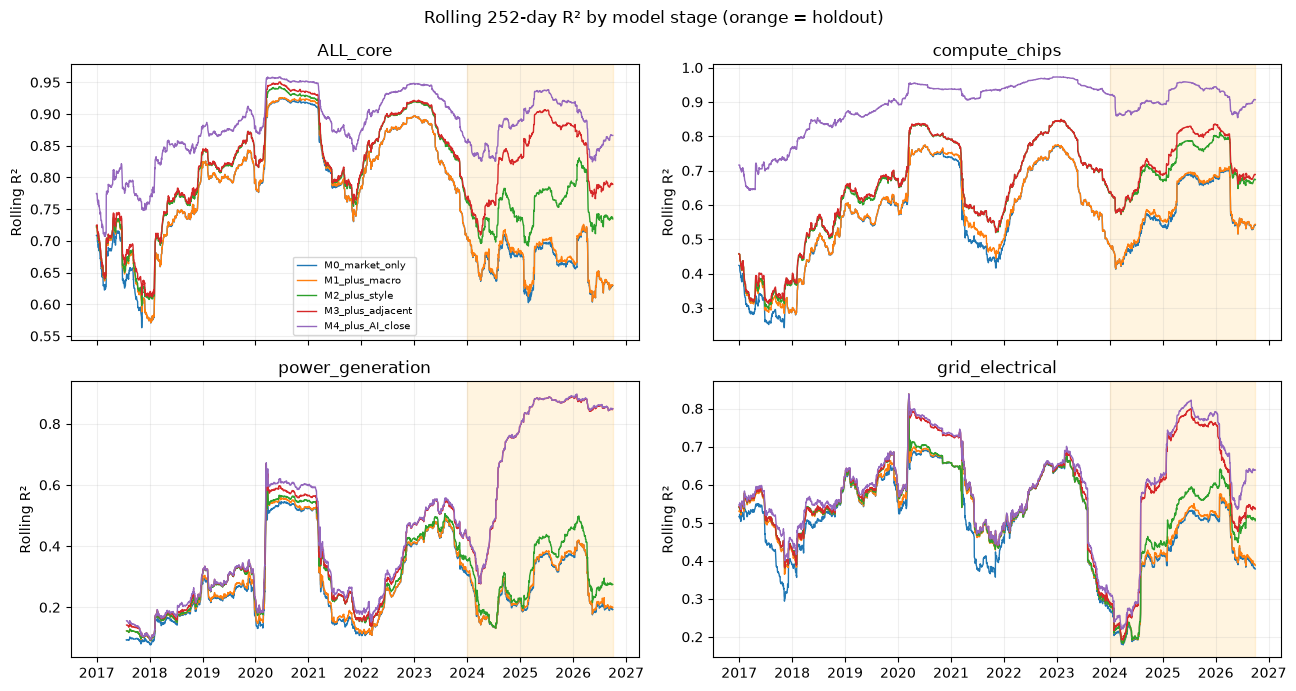

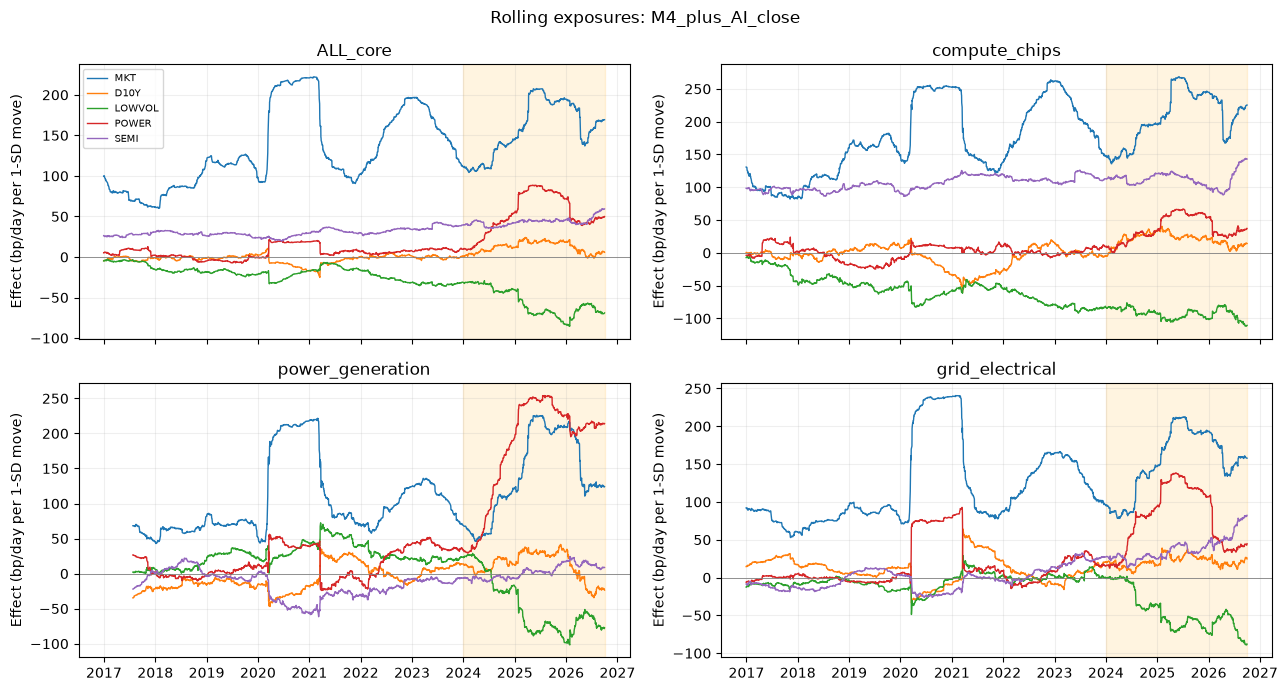

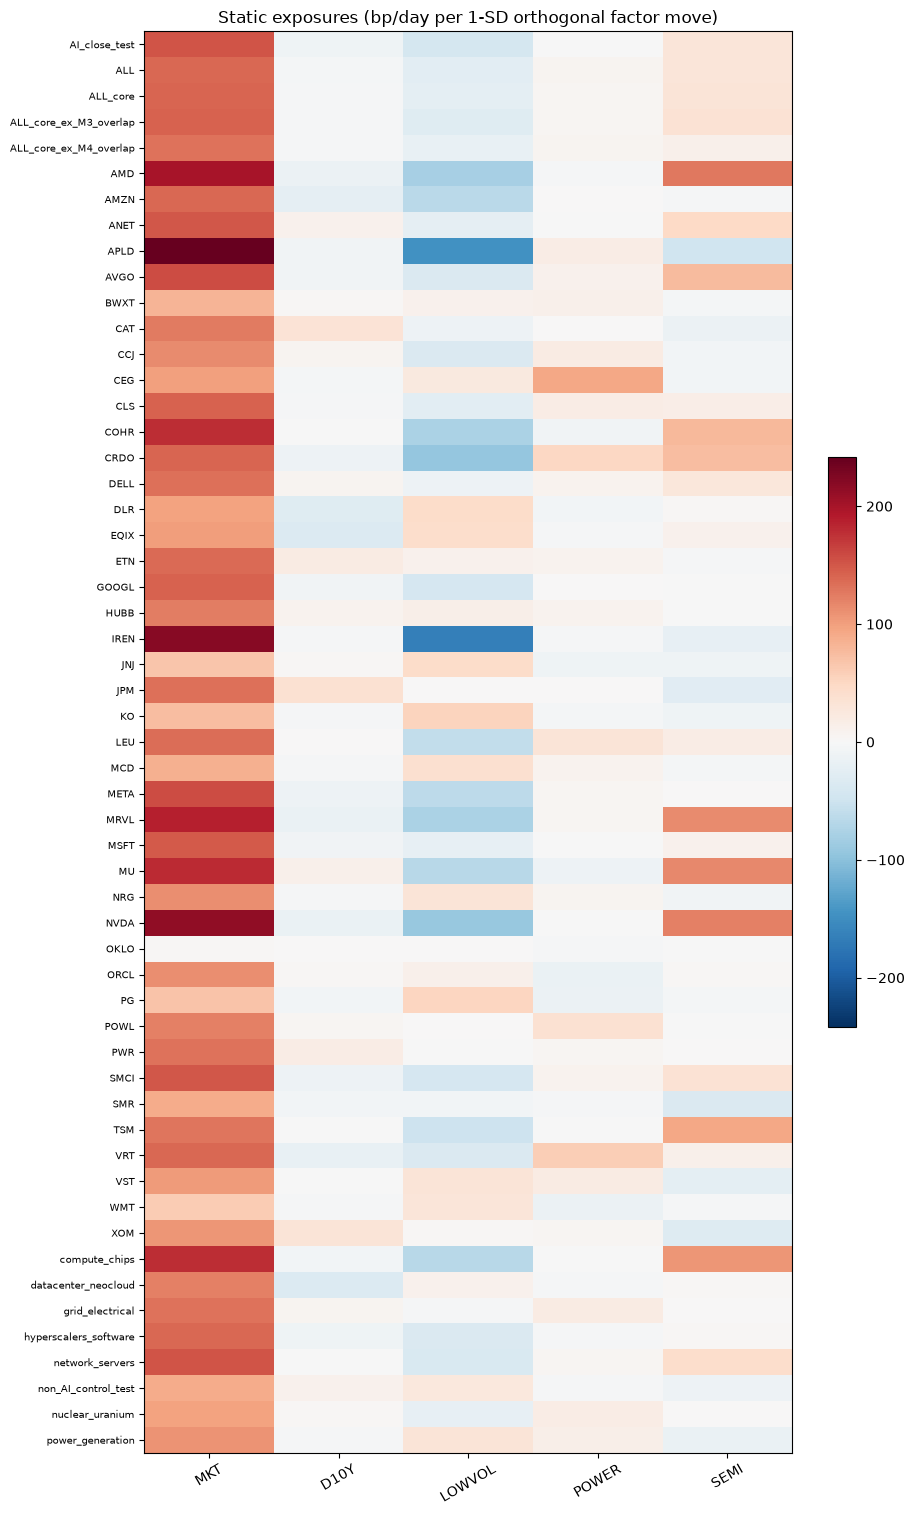

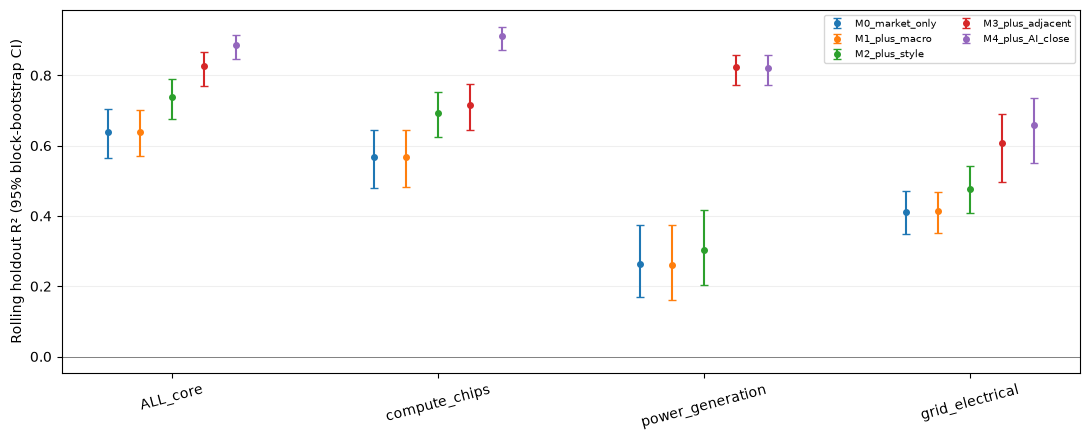

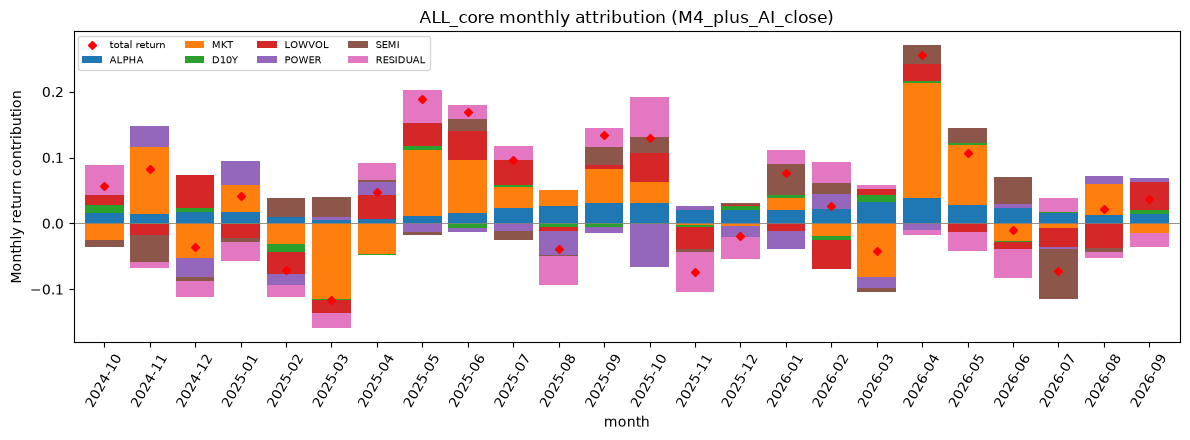

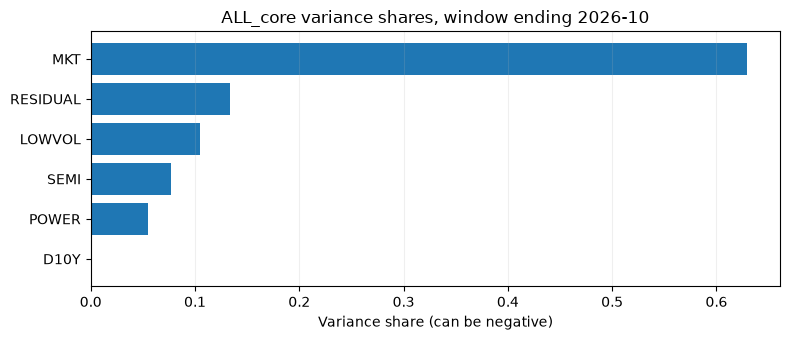

In [6]:
# Rolling R² by stage.
rf = R["rolling_fit"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, target in zip(axes.flat, key_targets):
    for model in lm.MODELS:
        s = rf[(rf["model"] == model) & (rf["target"] == target)]
        ax.plot(s["date"], s["r2"], lw=1, label=model)
    ax.axvspan(pd.Timestamp(lm.HOLD_START), pd.Timestamp(lm.HOLD_END), color="orange", alpha=0.12)
    ax.set_title(target)
    ax.set_ylabel("Rolling R²")
    ax.grid(alpha=0.2)
for ax in axes.flat[len(key_targets):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7)
fig.suptitle("Rolling 252-day R² by model stage (orange = holdout)")
fig.tight_layout()
plt.show()

# Rolling exposures for the largest model.
gamma = R["rolling_gamma"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, target in zip(axes.flat, key_targets):
    sub = gamma[gamma["target"] == target].pivot(index="date", columns="factor", values="effect_1sd_bp")
    for factor in factors:
        if factor in sub:
            ax.plot(sub.index, sub[factor], lw=1, label=factor)
    ax.axvspan(pd.Timestamp(lm.HOLD_START), pd.Timestamp(lm.HOLD_END), color="orange", alpha=0.12)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(target)
    ax.set_ylabel("Effect (bp/day per 1-SD move)")
    ax.grid(alpha=0.2)
for ax in axes.flat[len(key_targets):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7)
fig.suptitle(f"Rolling exposures: {lm.PRIMARY_MODEL}")
fig.tight_layout()
plt.show()

# Static exposure heatmap for all modeled targets.
heat = coef.pivot(index="target", columns="factor", values="effect_1sd_bp").reindex(columns=factors)
values = heat.to_numpy(dtype=float)
limit = np.nanmax(np.abs(values)) if np.isfinite(values).any() else 1.0
fig, ax = plt.subplots(figsize=(1.25 * len(factors) + 3, 0.25 * len(heat) + 1.5))
image = ax.imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(factors)), factors, rotation=30)
ax.set_yticks(range(len(heat)), heat.index, fontsize=7)
ax.set_title("Static exposures (bp/day per 1-SD orthogonal factor move)")
fig.colorbar(image, ax=ax, fraction=0.04)
fig.tight_layout()
plt.show()

# Holdout rolling R² and its block-bootstrap confidence interval.
oos_plot = rolling_holdout[rolling_holdout["target"].isin(key_targets)]
fig, ax = plt.subplots(figsize=(11, 4.5))
n_models = len(lm.MODELS)
for j, model in enumerate(lm.MODELS):
    s = oos_plot[oos_plot["model"] == model].set_index("target").reindex(key_targets).dropna(subset=["r2_oos"])
    x = np.array([key_targets.index(t) for t in s.index]) + (j - (n_models - 1) / 2) * 0.12
    yerr = [s["r2_oos"] - s["lo"], s["hi"] - s["r2_oos"]]
    ax.errorbar(x, s["r2_oos"], yerr=yerr, fmt="o", ms=4, capsize=3, label=model)
ax.axhline(0, color="grey", lw=0.7)
ax.set_xticks(range(len(key_targets)), key_targets, rotation=15)
ax.set_ylabel("Rolling holdout R² (95% block-bootstrap CI)")
ax.legend(fontsize=7, ncol=2)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

# Monthly attribution for ALL_core.
sub = am[am["target"] == "ALL_core"].set_index("month").tail(24)
if not sub.empty:
    names = [c for c in ["ALPHA", *factors, "RESIDUAL"] if c in sub]
    fig, ax = plt.subplots(figsize=(12, 4.5))
    sub[names].plot(kind="bar", stacked=True, ax=ax, width=0.85)
    ax.plot(np.arange(len(sub)), sub["total_return"], "D", color="red", ms=4, label="total return")
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_ylabel("Monthly return contribution")
    ax.set_title(f"ALL_core monthly attribution ({lm.PRIMARY_MODEL})")
    ax.tick_params(axis="x", labelrotation=60)
    ax.legend(fontsize=7, ncol=4)
    fig.tight_layout()
    plt.show()

# Latest variance shares; bars start at zero because shares may be negative.
if not rm.empty:
    last_risk = rm[(rm["month"] == latest_month) & (rm["target"] == "ALL_core")].sort_values("share")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.barh(last_risk["component"], last_risk["share"], color="tab:blue")
    ax.axvline(0, color="black", lw=0.7)
    ax.set_xlabel("Variance share (can be negative)")
    ax.set_title(f"ALL_core variance shares, window ending {latest_month}")
    ax.grid(axis="x", alpha=0.2)
    fig.tight_layout()
    plt.show()

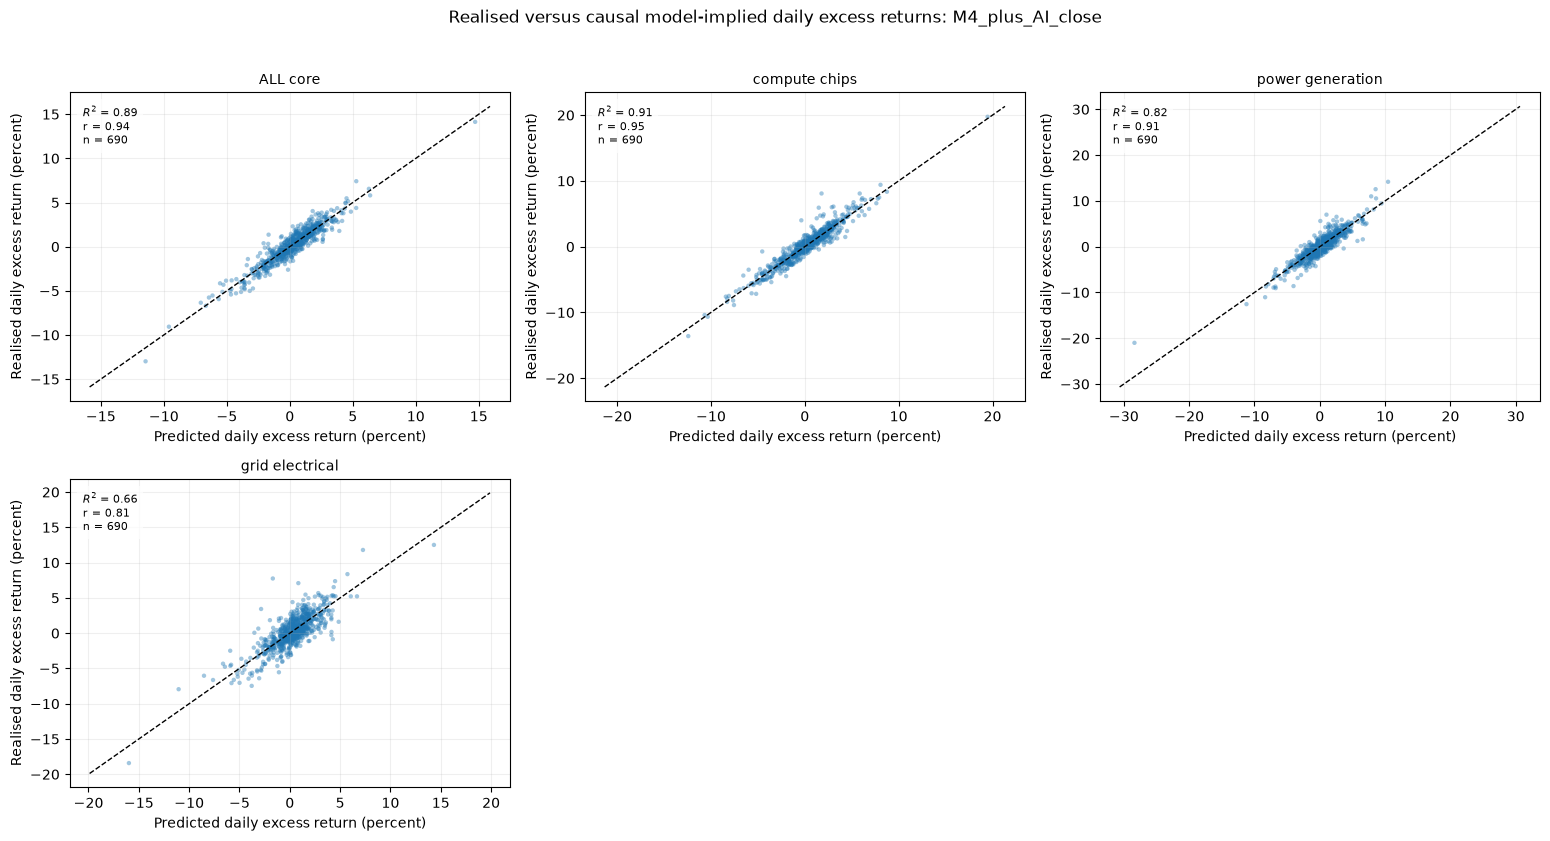

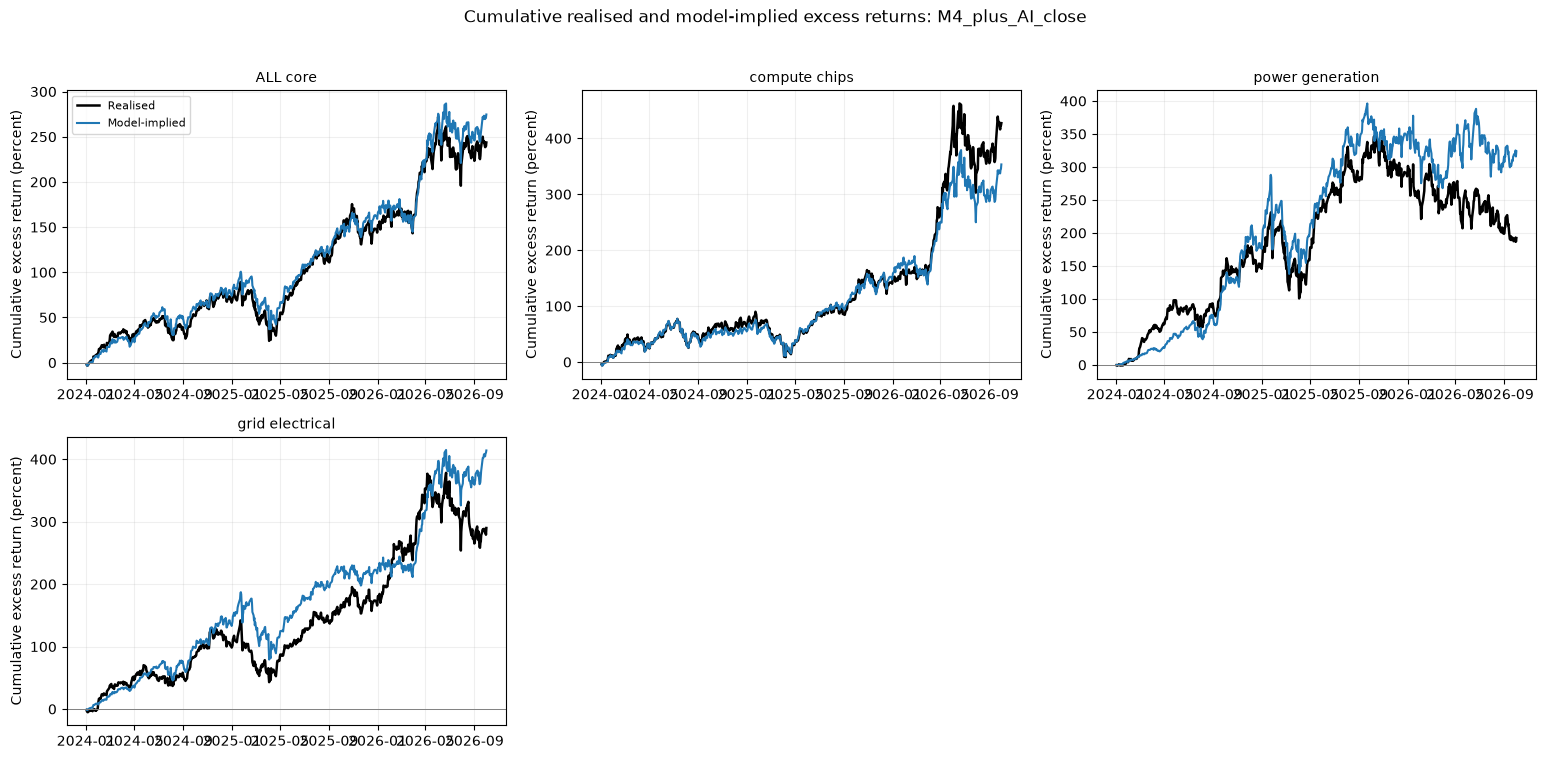

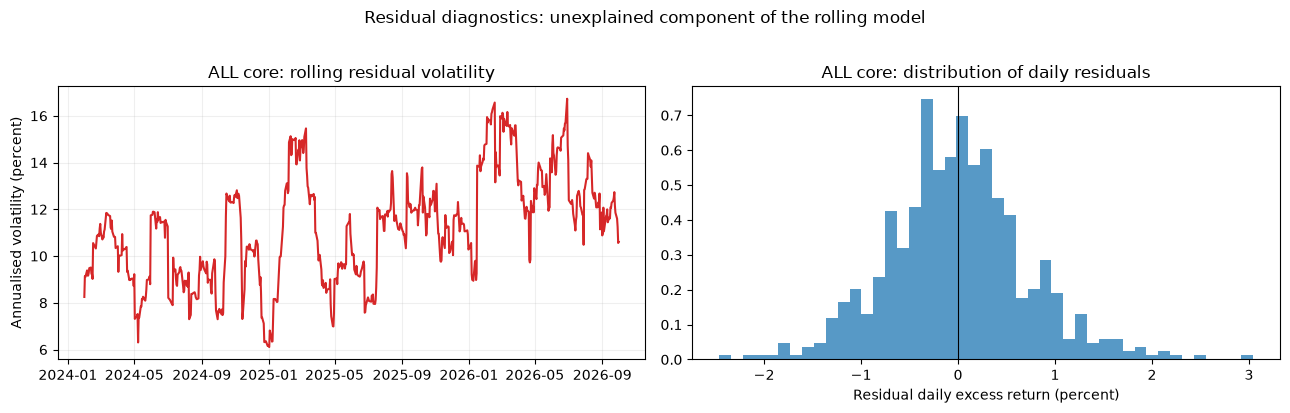

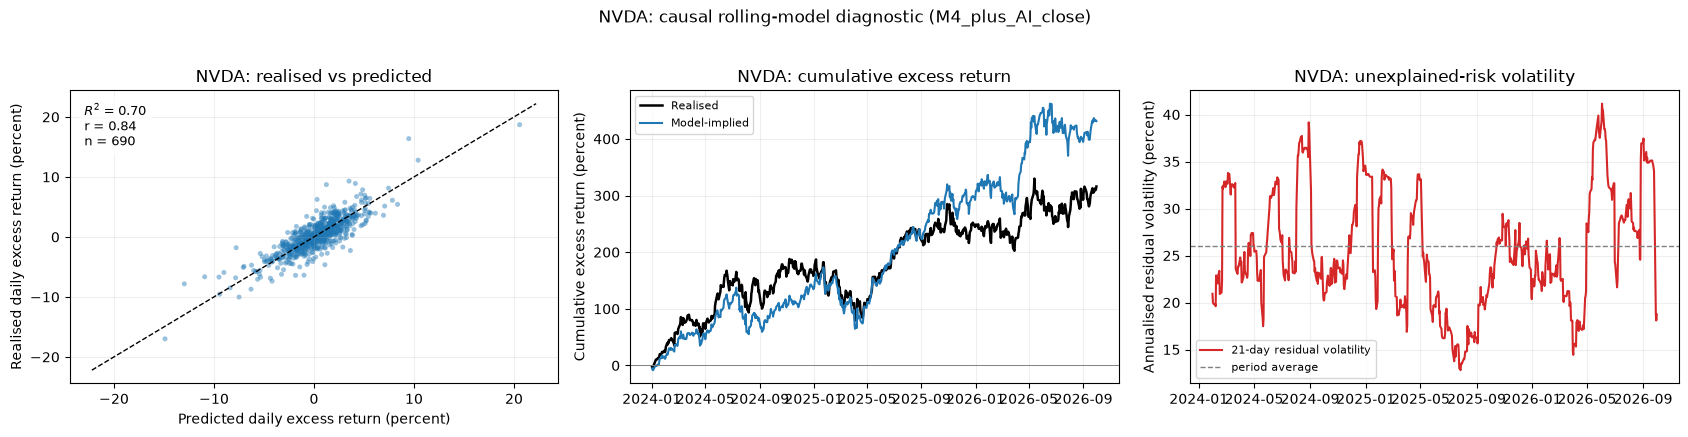

,target,excess_return,ALPHA,MKT,D10Y,LOWVOL,POWER,SEMI,RESIDUAL,predicted_excess,residual
date,,,,,,,,,,,
2024-01-02,NVDA,-0.027547,0.003604,-0.011744,-0.000213,-0.028948,-0.001617,-0.014782,0.026153,-0.053700,0.026153
2024-01-03,NVDA,-0.012643,0.003520,-0.017009,0.000165,-0.011345,0.000062,-0.001362,0.013326,-0.025969,0.013326
2024-01-04,NVDA,0.008811,0.003512,-0.006965,-0.000322,-0.001135,0.000129,-0.000178,0.013769,-0.004958,0.013769
2024-01-05,NVDA,0.022689,0.003627,0.002352,-0.000211,0.009290,-0.000249,0.000505,0.007374,0.015315,0.007374
2024-01-08,NVDA,0.064074,0.003651,0.028415,0.000105,0.004277,-0.000589,0.015488,0.012728,0.051346,0.012728
...,...,...,...,...,...,...,...,...,...,...,...
2026-09-25,NVDA,0.002020,0.000093,0.010009,0.001489,0.000494,0.000119,-0.001297,-0.008886,0.010906,-0.008886
2026-09-28,NVDA,0.016678,0.000071,-0.014407,0.002414,0.001888,0.000673,0.000024,0.026016,-0.009338,0.026016
2026-09-29,NVDA,-0.007371,0.000149,-0.003773,0.000445,0.000233,0.001452,0.002422,-0.008299,0.000928,-0.008299


In [8]:
lm.plot_prediction_diagnostics(R, targets=key_targets)
lm.plot_stock_prediction_diagnostics(R, "NVDA")

## How to draw a conclusion

Compare each stage's rolling holdout R² and its incremental confidence interval. If an added factor does not produce a stable improvement, the simpler model may be preferable. Check the overlap flags for `POWER` and `SEMI`, since their ETFs can hold stocks in the target groups. The result is specific to these representative factors, the chosen dates, and this stock universe; changing the representative within a category can change the conclusion.